# 02 — Bronze: perfilado

Exploración de los CSV antes de la capa Silver. Se lee **con Spark, sin inferir tipos**, y no se transforma nada. Este notebook **no evalúa reglas de calidad**: las de Bronze están en `01_bronze_descarga` y las de Silver en sus notebooks. Aquí solo se mira qué traen los archivos y cómo se van a leer en Silver.

| Sección | Contenido |
| --- | --- |
| 1 | Formato real de cada archivo (SIAF → SISMEPRE → RENAMU) |
| 2 | F1 SIAF: columnas, métricas por año, perfil de columnas, ejecutoras, unicidad |
| 3 | F2 SISMEPRE: qué contiene cada archivo → llaves → columnas de conexión → clasificación A–G |
| 4 | F3 RENAMU: inventario por edición → ediciones 2020–2026 |
| 5 | Conexión de prueba entre las tres fuentes |

## 0. Configuración

In [2]:
import sys
from pathlib import Path

RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "ARQUITECTURA.md").exists())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import re, logging
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

from src.config import cargar_config, ruta
from src.spark import crear_sesion
from src import bronze
from src.perfilado import detectar_formato, leer_csv, a_pandas, perfil_columnas

pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200)
cfg = cargar_config()
spark = crear_sesion("bronze_perfilado")

# Inventario desde el manifest (lista los archivos vigentes de Bronze, D-014)
man = pd.DataFrame(bronze.leer_manifest()["archivos"])
man["ext"] = man["archivo"].str.rsplit(".", n=1).str[-1].str.lower()
csvs = man[man["ext"] == "csv"].copy()
csvs["abs"] = csvs["ruta"].map(lambda r: str(RAIZ / r))

print(csvs.groupby("fuente").agg(csv=("ruta", "count"), GB=("bytes", lambda s: round(s.sum() / 1e9, 3))).to_string())

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/22 13:48:24 WARN Utils: Your hostname, Rodrigo, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/22 13:48:24 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/22 13:48:24 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


         csv     GB
fuente             
F1        18  7.336
F2         7  0.059
F3      1028  0.272


## 1. Formato real de cada archivo (encoding y delimitador)

In [2]:
fmt_rows = []
for r in csvs.itertuples():
    f = detectar_formato(Path(r.abs))
    fmt_rows.append({"fuente": r.fuente, "anio": r.anio, "ruta": r.ruta, "abs": r.abs, "archivo": r.archivo,
                     "filas_fisicas": r.filas, **{k: v for k, v in f.items() if k != "columnas"}, "lista_columnas": f["columnas"]})
df_fmt = pd.DataFrame(fmt_rows)
VER = ["archivo", "encoding", "bom", "delimitador", "salto_linea", "n_columnas", "filas_fisicas"]

### 1.1 F1 SIAF

In [3]:
display(df_fmt[df_fmt["fuente"] == "F1"].sort_values("anio")[["anio"] + VER])

,anio,archivo,encoding,bom,delimitador,salto_linea,n_columnas,filas_fisicas
1028,2009.0,2009-Ingreso.csv,UTF-8,False,",",CRLF,36,1235428.0
1029,2010.0,2010-Ingreso.csv,UTF-8,False,",",CRLF,36,1320104.0
1030,2011.0,2011-Ingreso.csv,UTF-8,False,",",CRLF,36,1348362.0
1031,2012.0,2012-Ingreso.csv,UTF-8,False,",",CRLF,36,759578.0
1032,2013.0,2013-Ingreso.csv,UTF-8,False,",",CRLF,36,721663.0
1033,2014.0,2014-Ingreso.csv,UTF-8,False,",",CRLF,36,753998.0
1034,2015.0,2015-Ingreso.csv,UTF-8,False,",",CRLF,36,781007.0
1035,2016.0,2016-Ingreso.csv,UTF-8,False,",",CRLF,36,764731.0
1036,2017.0,2017-Ingreso.csv,UTF-8,False,",",CRLF,36,683816.0
1037,2018.0,2018-Ingreso.csv,UTF-8,False,",",CRLF,36,656859.0


### 1.2 F2 SISMEPRE

In [4]:
display(df_fmt[df_fmt["fuente"] == "F2"].sort_values("archivo")[VER])

,archivo,encoding,bom,delimitador,salto_linea,n_columnas,filas_fisicas
1046,rentas_ano_aplicacion.csv,UTF-8,False,",",CRLF,9,27.0
1047,rentas_entidad_estado.csv,UTF-8,False,",",CRLF,13,20391.0
1048,rentas_esat_estadistica_atm.csv,UTF-8,False,",",CRLF,42,149546.0
1049,rentas_estadistica.csv,UTF-8,False,",",CRLF,7,260.0
1050,rentas_formulario.csv,UTF-8,False,",",CRLF,10,108.0
1051,rentas_preguntas.csv,UTF-8,False,",",CRLF,15,836.0
1052,rentas_respuestas.csv,UTF-8,False,",",CRLF,11,322675.0


### 1.3 F3 RENAMU (resumen por edición; más de 1 000 archivos)

In [5]:
f3 = df_fmt[df_fmt["fuente"] == "F3"].copy()
f3["anio"] = f3["anio"].astype(int)
f3["formulario"] = f3["ruta"].map(lambda r: "F02 centros poblados" if "_F02_" in r else "F01 municipalidades")
display(f3.groupby(["anio", "formulario"]).agg(
    csv=("ruta", "count"), encoding=("encoding", lambda s: "/".join(sorted(set(s)))), bom=("bom", "any"),
    delimitador=("delimitador", lambda s: "/".join(sorted(set(s)))), salto_linea=("salto_linea", lambda s: "/".join(sorted(set(s))))))

,,csv,encoding,bom,delimitador,salto_linea
anio,formulario,,,,,
2009,F01 municipalidades,98,ISO-8859-1,False,;,CRLF
2010,F01 municipalidades,98,ISO-8859-1,False,;,CRLF
2011,F01 municipalidades,98,ISO-8859-1,False,;,CRLF
2012,F01 municipalidades,108,ISO-8859-1,False,;,CRLF
2013,F01 municipalidades,107,ISO-8859-1,False,;,CRLF
2014,F01 municipalidades,96,ISO-8859-1,False,;,CRLF
2015,F01 municipalidades,115,ISO-8859-1,False,;,CRLF
2016,F01 municipalidades,111,ISO-8859-1,False,;,CRLF
2017,F01 municipalidades,116,ISO-8859-1,False,;,CRLF


## 2. F1 SIAF — Presupuesto y ejecución de ingreso

### 2.1 Columnas esperadas vs. reales

In [6]:
siaf = df_fmt[df_fmt["fuente"] == "F1"].sort_values("anio")
ESPERADAS_SIAF = siaf[siaf["anio"] == 2024]["lista_columnas"].iloc[0] 
cols_siaf = pd.DataFrame([{
    "anio": int(r.anio), "n_columnas": r.n_columnas, "iguales_y_en_orden": r.lista_columnas == ESPERADAS_SIAF,
    "faltan": ", ".join(sorted(set(ESPERADAS_SIAF) - set(r.lista_columnas))) or "—",
    "sobran": ", ".join(sorted(set(r.lista_columnas) - set(ESPERADAS_SIAF))) or "—",
} for r in siaf.itertuples()])
display(cols_siaf)
print("Columnas:", ESPERADAS_SIAF)

FMT_SIAF = detectar_formato(RAIZ / siaf.iloc[-1]["ruta"])
df_siaf = (leer_csv(spark, siaf["abs"].tolist(), FMT_SIAF)
           .withColumn("anio_archivo", F.regexp_extract(F.input_file_name(), r"(\d{4})-Ingreso", 1).cast("int")))

,anio,n_columnas,iguales_y_en_orden,faltan,sobran
0,2009,36,True,—,—
1,2010,36,True,—,—
2,2011,36,True,—,—
3,2012,36,True,—,—
4,2013,36,True,—,—
5,2014,36,True,—,—
6,2015,36,True,—,—
7,2016,36,True,—,—
8,2017,36,True,—,—
9,2018,36,True,—,—


Columnas: ['ANO_DOC', 'MES_DOC', 'NIVEL_GOBIERNO', 'NIVEL_GOBIERNO_NOMBRE', 'SECTOR', 'SECTOR_NOMBRE', 'PLIEGO', 'PLIEGO_NOMBRE', 'SEC_EJEC', 'EJECUTORA', 'EJECUTORA_NOMBRE', 'DEPARTAMENTO_EJECUTORA', 'DEPARTAMENTO_EJECUTORA_NOMBRE', 'PROVINCIA_EJECUTORA', 'PROVINCIA_EJECUTORA_NOMBRE', 'DISTRITO_EJECUTORA', 'DISTRITO_EJECUTORA_NOMBRE', 'FUENTE_FINANCIAMIENTO', 'FUENTE_FINANCIAMIENTO_NOMBRE', 'RUBRO', 'RUBRO_NOMBRE', 'TIPO_RECURSO', 'TIPO_RECURSO_NOMBRE', 'GENERICA', 'GENERICA_NOMBRE', 'SUBGENERICA', 'SUBGENERICA_NOMBRE', 'SUBGENERICA_DET', 'SUBGENERICA_DET_NOMBRE', 'ESPECIFICA', 'ESPECIFICA_NOMBRE', 'ESPECIFICA_DET', 'ESPECIFICA_DET_NOMBRE', 'MONTO_PIA', 'MONTO_PIM', 'MONTO_RECAUDADO']


### 2.2 Pasada 1 — métricas por año

In [7]:
num = lambda c: F.col(c).cast("double")
es_m = F.col("NIVEL_GOBIERNO") == "M"
anual = (df_siaf.groupBy("anio_archivo").agg(
    F.count("*").alias("filas_spark"),
    F.sum(es_m.cast("long")).alias("filas_M"),
    F.sum((F.col("NIVEL_GOBIERNO") == "R").cast("long")).alias("filas_R"),
    F.sum((F.col("NIVEL_GOBIERNO") == "E").cast("long")).alias("filas_E"),
    F.sum((~F.col("NIVEL_GOBIERNO").isin("E", "M", "R")).cast("long")).alias("filas_otro_nivel"),
    F.sum((F.col("ANO_DOC").cast("int") != F.col("anio_archivo")).cast("long")).alias("ano_doc_distinto"),
    F.min(F.col("MES_DOC").cast("int")).alias("mes_min"), F.max(F.col("MES_DOC").cast("int")).alias("mes_max"),
    F.sum(((num("MONTO_PIA") == 0) & (num("MONTO_PIM") == 0) & (num("MONTO_RECAUDADO") == 0)).cast("long")).alias("filas_montos_cero"),
    F.sum((num("MONTO_RECAUDADO") < 0).cast("long")).alias("recaudado_negativo"),
    F.sum((num("MONTO_PIM") < 0).cast("long")).alias("pim_negativo"),
    F.sum(F.when(es_m, num("MONTO_PIA"))).alias("pia_M"),
    F.sum(F.when(es_m & (F.col("MES_DOC") == "1"), num("MONTO_PIA"))).alias("pia_M_enero"),
    F.sum(F.when(es_m, num("MONTO_PIM"))).alias("pim_M"),
    F.sum(F.when(es_m, num("MONTO_RECAUDADO"))).alias("recaudado_M"),
    F.countDistinct(F.when(es_m, F.concat_ws("-", "SEC_EJEC", "MES_DOC"))).alias("ejecutora_mes_M"),
)).orderBy("anio_archivo")
df_anual = a_pandas(anual)
df_anual = df_anual.merge(siaf[["anio", "filas_fisicas"]].rename(columns={"anio": "anio_archivo"}).astype({"anio_archivo": int}), on="anio_archivo")
df_anual["dif_spark_vs_fisico"] = df_anual["filas_spark"] - df_anual["filas_fisicas"].astype(int)
df_anual["filas_M_por_ejecutora_mes"] = (df_anual["filas_M"] / df_anual["ejecutora_mes_M"]).round(1)
df_anual["pct_pia_en_enero"] = (100 * df_anual["pia_M_enero"] / df_anual["pia_M"]).round(1)
df_anual["pct_filas_montos_cero"] = (100 * df_anual["filas_montos_cero"] / df_anual["filas_spark"]).round(1)
for c in ("pia_M", "pim_M", "recaudado_M"):
    df_anual[c + "_millones"] = (df_anual[c] / 1e6).round(1)
df_anual = df_anual.drop(columns=["pia_M", "pim_M", "recaudado_M", "pia_M_enero", "ejecutora_mes_M"]).set_index("anio_archivo")
display(df_anual)

,filas_spark,filas_M,filas_R,filas_E,filas_otro_nivel,ano_doc_distinto,mes_min,mes_max,filas_montos_cero,recaudado_negativo,pim_negativo,filas_fisicas,dif_spark_vs_fisico,filas_M_por_ejecutora_mes,pct_pia_en_enero,pct_filas_montos_cero,pia_M_millones,pim_M_millones,recaudado_M_millones
anio_archivo,,,,,,,,,,,,,,,,,,,
2009,1235428,1080470,90407,64551,0,0,1,12,349137,3309,90,1235428.0,0,49.1,7.7,28.3,11999.8,20695.9,18496.6
2010,1320104,1159789,94370,65945,0,0,1,12,415152,4539,77,1320104.0,0,52.7,7.9,31.4,9138.8,20936.5,20161.7
2011,1348362,1185119,97197,66046,0,0,1,12,424588,4444,12,1348362.0,0,53.8,7.7,31.5,10793.5,21314.0,20858.4
2012,759578,638925,70586,50067,0,0,1,12,149809,4894,17,759578.0,0,28.9,100.0,19.7,14826.2,27217.4,26288.4
2013,721663,590342,76959,54362,0,0,1,12,146111,4722,36,721663.0,0,26.8,100.0,20.2,17559.5,28965.6,26579.9
2014,753998,611673,83258,59067,0,0,1,12,150219,5384,258,753998.0,0,27.6,100.0,19.9,16353.0,27088.6,25872.6
2015,781007,632600,86962,61445,0,0,1,12,149074,5295,3668,781007.0,0,28.3,100.0,19.1,15230.7,24004.5,23399.8
2016,764731,613544,89084,62103,0,0,1,12,148618,6241,183,764731.0,0,27.2,100.0,19.4,14269.9,26468.3,25979.1
2017,683816,550949,77922,54945,0,0,1,12,44609,7862,673,683816.0,0,24.4,100.0,6.5,14553.4,29127.8,28884.8


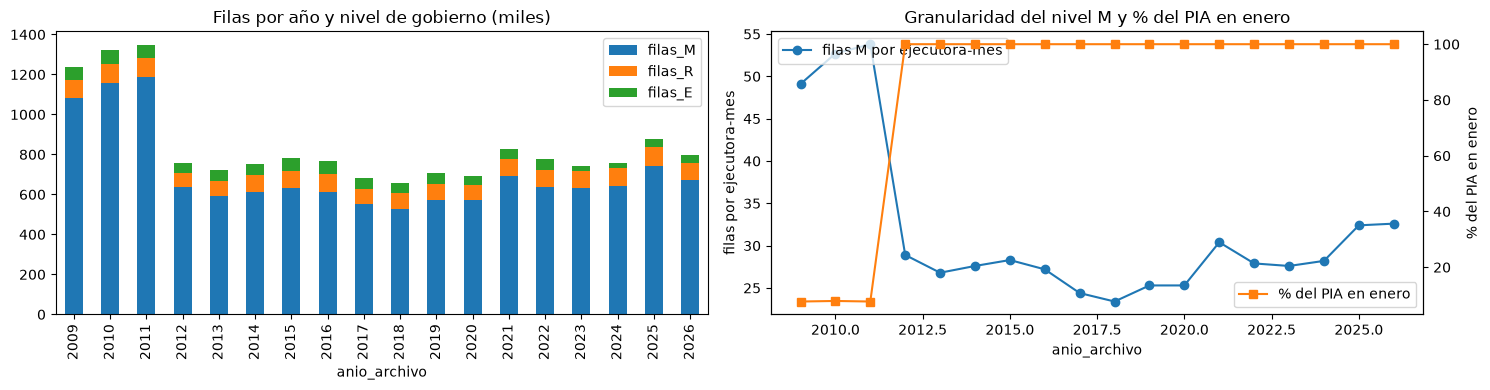

In [8]:
# Visualización: filas por año y nivel, granularidad del nivel M y % del PIA registrado en enero
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
df_anual[["filas_M", "filas_R", "filas_E"]].div(1e3).plot.bar(stacked=True, ax=ax[0], title="Filas por año y nivel de gobierno (miles)")
df_anual["filas_M_por_ejecutora_mes"].plot(ax=ax[1], marker="o", label="filas M por ejecutora-mes", title="Granularidad del nivel M y % del PIA en enero")
ax[1].set_ylabel("filas por ejecutora-mes"); ax[1].legend(loc="upper left")
ax_r = ax[1].twinx(); df_anual["pct_pia_en_enero"].plot(ax=ax_r, marker="s", color="tab:orange", label="% del PIA en enero")
ax_r.set_ylabel("% del PIA en enero"); ax_r.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 2.3 Pasada 2 — perfil de columnas (nulos, vacíos y qué contiene cada columna)

`contenido`: **números** = todos los valores con dato son numéricos (montos o códigos) · **texto** = nombres u otros textos · **mixto** = parte y parte.

In [9]:
perf_siaf = perfil_columnas(df_siaf.drop("anio_archivo"), "F1", "siaf")
display(perf_siaf.drop(columns=["fuente", "tabla"]).set_index("columna"))

# ¿En qué nivel de gobierno están los vacíos de SECTOR y PLIEGO?
display(a_pandas(df_siaf.groupBy("NIVEL_GOBIERNO").agg(F.count("*").alias("filas"),
        F.sum((F.trim("SECTOR") == "").cast("long")).alias("sector_vacio"), F.sum((F.trim("PLIEGO") == "").cast("long")).alias("pliego_vacio"))))

26/11/22 13:38:17 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
26/11/22 13:38:17 WARN DAGScheduler: Broadcasting large task binary with size 2.8 MiB


26/11/22 13:39:52 WARN DAGScheduler: Broadcasting large task binary with size 6.7 MiB


,filas,nulos,vacios,pct_nulo_o_vacio,distintos_aprox,largo_min,largo_max,contenido
columna,,,,,,,,
ANO_DOC,15204055,0,0,0.00,18,4,4,números
MES_DOC,15204055,0,0,0.00,12,1,2,números
NIVEL_GOBIERNO,15204055,0,0,0.00,3,1,1,texto
NIVEL_GOBIERNO_NOMBRE,15204055,0,0,0.00,3,17,20,texto
SECTOR,15204055,0,12751022,83.87,33,1,2,números
SECTOR_NOMBRE,15204055,0,12751022,83.87,36,1,50,texto
PLIEGO,15204055,0,12751022,83.87,189,1,3,números
PLIEGO_NOMBRE,15204055,0,12751022,83.87,281,1,107,texto
SEC_EJEC,15204055,0,0,0.00,2998,1,6,números


,NIVEL_GOBIERNO,filas,sector_vacio,pliego_vacio
0,M,12751022,12751022,12751022
1,R,1525420,0,0
2,E,927613,0,0


### 2.4 Pasada 3 — ejecutoras del nivel M y consistencia de `SEC_EJEC`

In [10]:
ubigeo = F.concat(F.lpad("DEPARTAMENTO_EJECUTORA", 2, "0"), F.lpad("PROVINCIA_EJECUTORA", 2, "0"), F.lpad("DISTRITO_EJECUTORA", 2, "0"))
tipo_ejec = (F.when(F.col("EJECUTORA_NOMBRE").startswith("MUNICIPALIDAD DISTRITAL"), "Municipalidad distrital")
              .when(F.col("EJECUTORA_NOMBRE").startswith("MUNICIPALIDAD PROVINCIAL"), "Municipalidad provincial")
              .when(F.col("EJECUTORA_NOMBRE").startswith("MUNICIPALIDAD METROPOLITANA"), "Municipalidad metropolitana")
              .when(F.col("EJECUTORA_NOMBRE").startswith("MANCOMUNIDAD"), "Mancomunidad municipal")
              .otherwise("Otra"))
df_ejec = a_pandas(df_siaf.where(es_m).select(F.col("anio_archivo").alias("anio"), "SEC_EJEC", "EJECUTORA_NOMBRE",
                   ubigeo.alias("ubigeo"), tipo_ejec.alias("tipo_ejecutora"), F.length("DEPARTAMENTO_EJECUTORA").alias("largo_dep")).distinct())
display(df_ejec.drop_duplicates(["anio", "SEC_EJEC"]).pivot_table(index="anio", columns="tipo_ejecutora", values="SEC_EJEC", aggfunc="count", fill_value=0))

consist = df_ejec.groupby(["anio", "SEC_EJEC"]).agg(n_ubigeo=("ubigeo", "nunique"), n_nombre=("EJECUTORA_NOMBRE", "nunique"))
muni = df_ejec[df_ejec["tipo_ejecutora"].str.startswith("Municipalidad")]
tabla_consist = pd.DataFrame({
    "sec_ejec_con_varios_ubigeos": consist.groupby("anio")["n_ubigeo"].apply(lambda s: (s > 1).sum()),
    "sec_ejec_con_varios_nombres": consist.groupby("anio")["n_nombre"].apply(lambda s: (s > 1).sum()),
    "ubigeos_con_varias_municipalidades": muni.groupby(["anio", "ubigeo"])["SEC_EJEC"].nunique().gt(1).groupby("anio").sum(),
    "ejecutoras_con_codigo_de_1_digito": df_ejec[df_ejec["largo_dep"] == 1].groupby("anio")["SEC_EJEC"].nunique(),
}).fillna(0).astype(int)
display(tabla_consist)

tipo_ejecutora,Mancomunidad municipal,Municipalidad distrital,Municipalidad metropolitana,Municipalidad provincial
anio,,,,
2009,0,1639,1,194
2010,0,1639,0,195
2011,0,1642,0,195
2012,19,1643,0,195
2013,25,1644,1,194
2014,30,1651,1,195
2015,32,1658,1,195
2016,40,1677,1,195
2017,43,1678,1,195


,sec_ejec_con_varios_ubigeos,sec_ejec_con_varios_nombres,ubigeos_con_varias_municipalidades,ejecutoras_con_codigo_de_1_digito
anio,,,,
2009,0,0,0,0
2010,0,0,0,0
2011,0,0,0,0
2012,0,0,0,4
2013,0,1,0,0
2014,0,3,0,0
2015,0,0,0,0
2016,0,1,0,0
2017,0,1,0,0


### 2.5 Pasada 4 — duplicados y unicidad de la llave de negocio

In [11]:
LLAVE_SIAF = ["ANO_DOC", "MES_DOC", "SEC_EJEC", "FUENTE_FINANCIAMIENTO", "RUBRO", "TIPO_RECURSO",
              "GENERICA", "SUBGENERICA", "SUBGENERICA_DET", "ESPECIFICA", "ESPECIFICA_DET"]
todas = [c for c in df_siaf.columns if c != "anio_archivo"]
dups = a_pandas(df_siaf.groupBy("anio_archivo").agg(
    F.count("*").alias("filas"),
    (F.count("*") - F.countDistinct(F.sha2(F.concat_ws("|", *[F.coalesce(F.col(c), F.lit("∅")) for c in todas]), 256))).alias("duplicados_exactos"),
    (F.count("*") - F.countDistinct(F.concat_ws("|", *LLAVE_SIAF))).alias("duplicados_llave"),
).orderBy("anio_archivo")).set_index("anio_archivo")
display(dups.T)

anio_archivo,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
filas,1235428,1320104,1348362,759578,721663,753998,781007,764731,683816,656859,706695,692729,828317,774954,743452,758116,878733,795513
duplicados_exactos,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
duplicados_llave,0,21,64,70,3,27,20,16,20,7,5,9,3,4,4,0,16,2


## 3. F2 SISMEPRE — Meta del impuesto predial

### 3.1 Archivos: qué contiene cada uno y si se usaría

In [12]:
f2 = df_fmt[df_fmt["fuente"] == "F2"].sort_values("archivo")
SENSIBLES_F2 = {"CORREO", "USUARIO_ENVIO_ID"}          # datos personales: solo se cuentan
CONTENIDO_F2 = {   # (qué es, uso propuesto en Silver)
    "rentas_ano_aplicacion.csv":       ("Catálogo de años y periodos de evaluación (fechas de cierre)", "No (referencia)"),
    "rentas_entidad_estado.csv":       ("Una fila por municipalidad × año × periodo: estado de la meta y CLASIFICACION A–G", "Sí: clasificación A–G"),
    "rentas_esat_estadistica_atm.csv": ("Estadística del predial por municipalidad: emisión, base imponible, recaudación, contribuyentes, predios", "Sí: montos del predial"),
    "rentas_estadistica.csv":          ("Catálogo: año y mes de estadística que pide cada formulario", "No (referencia)"),
    "rentas_formulario.csv":           ("Catálogo de formularios de la meta", "No (referencia)"),
    "rentas_preguntas.csv":            ("Catálogo de preguntas de cada formulario", "No (referencia)"),
    "rentas_respuestas.csv":           ("Respuesta de cada municipalidad a cada pregunta", "Probablemente no"),
}
dfs_f2, resumen_f2 = {}, []
for r in f2.itertuples():
    d = leer_csv(spark, r.abs, detectar_formato(RAIZ / r.ruta), corrupto=True).cache()
    n, corr = d.count(), d.where(F.col("_corrupt_record").isNotNull()).count()
    dfs_f2[r.archivo] = d.where(F.col("_corrupt_record").isNull()).drop("_corrupt_record").cache()
    que, uso = CONTENIDO_F2[r.archivo]
    resumen_f2.append({"archivo": r.archivo, "contenido": que, "filas": n, "filas_mal_formadas": corr,
                       "columnas": len(dfs_f2[r.archivo].columns),
                       "datos_personales": ", ".join(sorted(SENSIBLES_F2 & set(d.columns))) or "—", "uso_propuesto": uso})
pd.set_option("display.max_colwidth", 110)
display(pd.DataFrame(resumen_f2).set_index("archivo"))

,contenido,filas,filas_mal_formadas,columnas,datos_personales,uso_propuesto
archivo,,,,,,
rentas_ano_aplicacion.csv,Catálogo de años y periodos de evaluación (fechas de cierre),27,0,9,—,No (referencia)
rentas_entidad_estado.csv,Una fila por municipalidad × año × periodo: estado de la meta y CLASIFICACION A–G,20391,0,13,"CORREO, USUARIO_ENVIO_ID",Sí: clasificación A–G
rentas_esat_estadistica_atm.csv,"Estadística del predial por municipalidad: emisión, base imponible, recaudación, contribuyentes, predios",149546,0,42,—,Sí: montos del predial
rentas_estadistica.csv,Catálogo: año y mes de estadística que pide cada formulario,260,0,7,—,No (referencia)
rentas_formulario.csv,Catálogo de formularios de la meta,108,0,10,—,No (referencia)
rentas_preguntas.csv,Catálogo de preguntas de cada formulario,836,0,15,—,No (referencia)
rentas_respuestas.csv,Respuesta de cada municipalidad a cada pregunta,322675,9,11,—,Probablemente no


### 3.2 Llave de cada archivo: ¿hay duplicados?

La llave es la combinación mínima de columnas que identifica cada fila. Se cuenta cuántas filas la repiten.

In [13]:
LLAVES_F2 = {
    "rentas_ano_aplicacion.csv":       ["ANO_APLICACION", "PERIODO"],
    "rentas_entidad_estado.csv":       ["SEC_EJEC", "ANO_APLICACION", "PERIODO"],
    "rentas_esat_estadistica_atm.csv": ["SEC_EJEC", "ANO_APLICACION", "PERIODO", "ANO_ESTADISTICA", "MES_ESTADISTICA", "FORMULARIO_ID"],
    "rentas_estadistica.csv":          ["ANO_APLICACION", "PERIODO", "FORMULARIO_ID", "ANO_ESTADISTICA", "MES_ESTADISTICA"],
    "rentas_formulario.csv":           ["ANO_APLICACION", "PERIODO", "FORMULARIO_ID"],
    "rentas_preguntas.csv":            ["ANO_APLICACION", "PERIODO", "PREGUNTA_ID"],
    "rentas_respuestas.csv":           ["SEC_EJEC", "ANO_APLICACION", "RESPUESTA_ID"],
}
llaves = []
for a, k in LLAVES_F2.items():
    d = dfs_f2[a]
    n, distintas = d.count(), d.select(*k).distinct().count()
    llaves.append({"archivo": a, "llave": " + ".join(k), "filas": n, "duplicados_por_llave": n - distintas})
display(pd.DataFrame(llaves).set_index("archivo"))

,llave,filas,duplicados_por_llave
archivo,,,
rentas_ano_aplicacion.csv,ANO_APLICACION + PERIODO,27,0
rentas_entidad_estado.csv,SEC_EJEC + ANO_APLICACION + PERIODO,20391,0
rentas_esat_estadistica_atm.csv,SEC_EJEC + ANO_APLICACION + PERIODO + ANO_ESTADISTICA + MES_ESTADISTICA + FORMULARIO_ID,149546,0
rentas_estadistica.csv,ANO_APLICACION + PERIODO + FORMULARIO_ID + ANO_ESTADISTICA + MES_ESTADISTICA,260,0
rentas_formulario.csv,ANO_APLICACION + PERIODO + FORMULARIO_ID,108,0
rentas_preguntas.csv,ANO_APLICACION + PERIODO + PREGUNTA_ID,836,0
rentas_respuestas.csv,SEC_EJEC + ANO_APLICACION + RESPUESTA_ID,322666,0


### 3.3 Columnas de conexión: cómo se unen los archivos entre sí y con las otras fuentes

In [14]:
CONEXION = ["ANO_APLICACION", "PERIODO", "FORMULARIO_ID", "PREGUNTA_ID", "SEC_EJEC", "UBIGEO"]
presencia = pd.DataFrame({a.replace("rentas_", "").replace(".csv", ""): {c: ("●" if c in d.columns else "") for c in CONEXION}
                          for a, d in dfs_f2.items()})
display(presencia)

def cobertura(hijo, padre, cols):
    h = dfs_f2[hijo].select(*cols).distinct(); p = dfs_f2[padre].select(*cols).distinct()
    n = h.count(); ok = h.join(p, cols, "inner").count()
    return {"de": hijo, "a": padre, "por": " + ".join(cols), "combinaciones": n, "encontradas": ok, "pct": round(100 * ok / n, 2) if n else None}
display(pd.DataFrame([
    cobertura("rentas_respuestas.csv", "rentas_preguntas.csv", ["ANO_APLICACION", "PERIODO", "FORMULARIO_ID", "PREGUNTA_ID"]),
    cobertura("rentas_preguntas.csv", "rentas_formulario.csv", ["ANO_APLICACION", "PERIODO", "FORMULARIO_ID"]),
    cobertura("rentas_respuestas.csv", "rentas_entidad_estado.csv", ["SEC_EJEC", "ANO_APLICACION", "PERIODO"]),
    cobertura("rentas_esat_estadistica_atm.csv", "rentas_entidad_estado.csv", ["SEC_EJEC", "ANO_APLICACION", "PERIODO"]),
    cobertura("rentas_entidad_estado.csv", "rentas_ano_aplicacion.csv", ["ANO_APLICACION", "PERIODO"]),
]))

,ano_aplicacion,entidad_estado,esat_estadistica_atm,estadistica,formulario,preguntas,respuestas
ANO_APLICACION,●,●,●,●,●,●,●
PERIODO,●,●,●,●,●,●,●
FORMULARIO_ID,,,●,●,●,●,●
PREGUNTA_ID,,,,,,●,●
SEC_EJEC,,●,●,,,,●
UBIGEO,,,●,,,,


,de,a,por,combinaciones,encontradas,pct
0,rentas_respuestas.csv,rentas_preguntas.csv,ANO_APLICACION + PERIODO + FORMULARIO_ID + PREGUNTA_ID,508,508,100.0
1,rentas_preguntas.csv,rentas_formulario.csv,ANO_APLICACION + PERIODO + FORMULARIO_ID,35,35,100.0
2,rentas_respuestas.csv,rentas_entidad_estado.csv,SEC_EJEC + ANO_APLICACION + PERIODO,3073,3073,100.0
3,rentas_esat_estadistica_atm.csv,rentas_entidad_estado.csv,SEC_EJEC + ANO_APLICACION + PERIODO,8142,8142,100.0
4,rentas_entidad_estado.csv,rentas_ano_aplicacion.csv,ANO_APLICACION + PERIODO,27,27,100.0


**Nota — cómo se conecta el SISMEPRE**

- **Todos** los archivos tienen `ANO_APLICACION + PERIODO` (año y periodo de la meta), y ninguno tiene filas duplicadas por su llave.
- **Por dentro**, los catálogos se unen por `FORMULARIO_ID` y `PREGUNTA_ID` (formulario → preguntas → respuestas).
- **Hacia afuera**, los archivos de municipalidades (`entidad_estado`, `esat_estadistica_atm`, `respuestas`) traen `SEC_EJEC`, el código de ejecutora del **SIAF**. `esat_estadistica_atm` trae además `UBIGEO`, el puente hacia el **RENAMU** (sección 5).

```
 formulario ──FORMULARIO_ID── preguntas ──PREGUNTA_ID── respuestas
                                                            │ SEC_EJEC
 ano_aplicacion ──ANO_APLICACION+PERIODO── entidad_estado ──┤ SEC_EJEC ──► SIAF
                                          (CLASIFICACION)   │
                                    esat_estadistica_atm ───┘ UBIGEO ───► RENAMU
```

### 3.4 Clasificación de municipalidades del Programa de Incentivos (`CLASIFICACION`, A–G)

La columna `CLASIFICACION` de `rentas_entidad_estado.csv`. Es la clasificación que el MEF usa en el *Programa de Incentivos a la Mejora de la Gestión Municipal* (PI). La tabla oficial está en el *Marco Conceptual del Programa de Incentivos*

| Tipo | Grupo (según el MEF) | Municipalidades (MEF 2018) |
| --- | --- | --- |
| A | Provinciales pertenecientes a ciudades principales | 74 |
| B | Provinciales no pertenecientes a ciudades principales | 122 |
| C | Distritales de Lima Metropolitana | 42 |
| D | Distritales de otras ciudades principales | 129 |
| E | Distritales no consideradas ciudades principales, con al menos 60 % de población urbana | 378 |
| F | Distritales no consideradas ciudades principales, con al menos 30 % y menos de 60 % de población urbana | 509 |
| G | Distritales no consideradas ciudades principales, con menos de 30 % de población urbana | 620 |
| | **Total** | **1 874** |

In [15]:
ee = dfs_f2["rentas_entidad_estado.csv"].select("SEC_EJEC", F.col("ANO_APLICACION").cast("int").alias("anio"), "CLASIFICACION")
tabla_clasif = (a_pandas(ee.groupBy("anio", "CLASIFICACION").agg(F.countDistinct("SEC_EJEC").alias("n")))
                .pivot_table(index="anio", columns="CLASIFICACION", values="n", fill_value=0).astype(int))
tabla_clasif["total"] = tabla_clasif.sum(axis=1)
display(tabla_clasif)
cambios = ee.where("anio >= 2019").groupBy("SEC_EJEC").agg(F.countDistinct("CLASIFICACION").alias("n")).where("n > 1").count()
total_con_tipo = ee.where("anio >= 2019").select("SEC_EJEC").distinct().count()
print("Municipalidades con tipo (2019–2026):", total_con_tipo, "| cambian de tipo desde 2019:", cambios)

CLASIFICACION,A,B,C,D,E,F,G,total
anio,,,,,,,,
2013,40,209,0,0,0,0,0,249
2014,40,209,0,0,0,0,0,249
2015,40,210,0,0,0,0,0,250
2016,40,210,0,0,0,0,0,250
2017,40,210,577,0,0,0,0,827
2018,40,210,578,0,0,0,0,828
2019,74,122,42,129,378,0,0,745
2020,74,122,42,129,378,0,0,745
2021,74,122,42,129,378,0,0,745


Municipalidades con tipo (2019–2026): 1449 | cambian de tipo desde 2019: 0


## 4. F3 RENAMU — Registro Nacional de Municipalidades

### 4.1 Inventario por edición y visualización: ¿desde qué año las ediciones son comparables?

In [16]:
f01 = f3[f3["formulario"] == "F01 municipalidades"]
cols_ed = {a: set().union(*map(set, g["lista_columnas"])) for a, g in f01.groupby("anio")}
base = {c.upper() for c in cols_ed[2022]}

# ¿La edición trae la tabla de ingresos con el predial? (búsqueda en sus diccionarios PDF)
logging.getLogger("pypdf").setLevel(logging.ERROR)
from pypdf import PdfReader
def tabla_ingresos(anio):
    pdfs = man[(man["fuente"] == "F3") & (man["anio"] == anio) & (man["ext"] == "pdf") & ~man["ruta"].str.contains("_F02_")]["ruta"]
    t = re.sub(r"\s+", " ", " ".join(" ".join((pg.extract_text() or "") for pg in PdfReader(RAIZ / p).pages) for p in pdfs))
    cod = re.findall(r"\b([PC]\d{2,3}(?:_\d+)+)\s+(?:Ingresos corrientes ?/ ?)?Impuestos[^/]{0,50}/ ?Predial", t)
    return bool(re.search(r"Impuestos( y contribucione ?s obligatorias)? ?/ ?Predial", t, re.I)), (cod[0] if cod else None)

inv = []
for a, g in f01.groupby("anio"):
    tiene, cod = tabla_ingresos(a)
    inv.append({"edicion": a, "csv": len(g), "filas_fisicas": int(g["filas_fisicas"].max()), "columnas": len(cols_ed[a]),
                "pct_columnas_comunes_2022": round(100 * len(base & {c.upper() for c in cols_ed[a]}) / len(base), 1),
                "una_tabla_por_municipalidad": len(g) == 1, "tabla_ingresos_predial": tiene, "codigo_predial": cod,
                "encoding": "/".join(sorted(set(g["encoding"])))})
df_inv = pd.DataFrame(inv).set_index("edicion")
display(df_inv)

,csv,filas_fisicas,columnas,pct_columnas_comunes_2022,una_tabla_por_municipalidad,tabla_ingresos_predial,codigo_predial,encoding
edicion,,,,,,,,
2009,98,17982,1178,8.2,False,True,P103_03,ISO-8859-1
2010,98,14878,1111,8.7,False,True,P103_04,ISO-8859-1
2011,98,14392,1106,8.5,False,True,P103_04,ISO-8859-1
2012,108,13186,1387,8.5,False,True,P113_04,ISO-8859-1
2013,107,12867,1363,8.2,False,False,NaN,ISO-8859-1
2014,96,11393,1175,8.3,False,False,NaN,ISO-8859-1
2015,115,3627,1803,27.8,False,True,P118_1_1_1,ISO-8859-1
2016,111,3320,1677,27.9,False,False,NaN,ISO-8859-1
2017,116,65531,1836,26.6,False,True,C115_1_1_1,ISO-8859-1


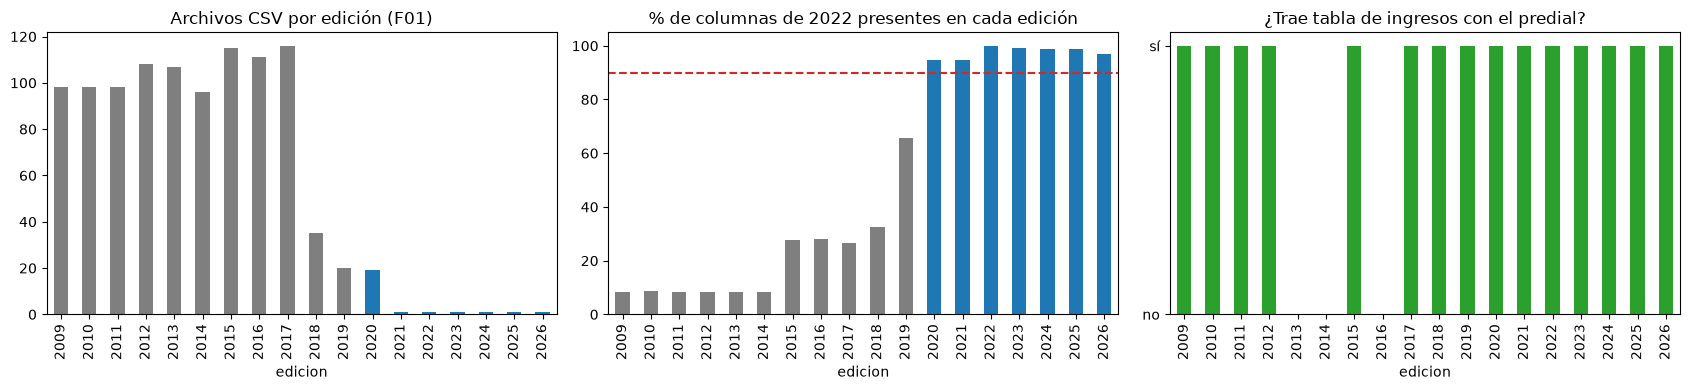

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
colores = ["tab:gray" if a < 2020 else "tab:blue" for a in df_inv.index]
df_inv["csv"].plot.bar(ax=ax[0], title="Archivos CSV por edición (F01)", color=colores)
df_inv["pct_columnas_comunes_2022"].plot.bar(ax=ax[1], title="% de columnas de 2022 presentes en cada edición", color=colores)
ax[1].axhline(90, ls="--", c="tab:red"); ax[1].set_ylim(0, 105)
df_inv["tabla_ingresos_predial"].astype(int).plot.bar(ax=ax[2], title="¿Trae tabla de ingresos con el predial?",
                                                       color=["tab:green" if v else "tab:red" for v in df_inv["tabla_ingresos_predial"]])
ax[2].set_yticks([0, 1], ["no", "sí"])
plt.tight_layout(); plt.show()

### 4.2 Ediciones 2020–2026 (rango de análisis): llave, tipo de municipalidad y tabla de ingresos

In [18]:
A0, A1 = cfg["anios"]["renamu_analisis"]
def _col(cols, nombre):
    return next((c for c in cols if c.lower() == nombre.lower()), None)
ren, ubigeos_renamu = [], {}
for r in f01[(f01["anio"] >= A0) & (f01["anio"] <= A1)].itertuples():
    pdf = a_pandas(leer_csv(spark, r.abs, detectar_formato(RAIZ / r.ruta)))     # ~1 900 filas: se revisa en pandas
    cols = list(pdf.columns)
    cu, ct = _col(cols, "Ubigeo"), _col(cols, "Tipomuni")
    ubi = pdf[cu] if cu else pdf[_col(cols, "ccdd")].str.zfill(2) + pdf[_col(cols, "ccpp")].str.zfill(2) + pdf[_col(cols, "ccdi")].str.zfill(2)
    valido = ubi.str.fullmatch(r"\d{6}").fillna(False)
    ubigeos_renamu.setdefault(r.anio, set()).update(ubi[valido])
    vacias = int(pdf.replace(r"^\s*$", None, regex=True).isna().all(axis=1).sum())   # filas sin ningún dato
    ren.append({"edicion": r.anio, "archivo": r.archivo, "filas": len(pdf), "filas_vacias": vacias, "columnas": len(cols), "ubigeo_origen": cu or "ccdd+ccpp+ccdi",
                "filas_sin_ubigeo_valido": int((~valido).sum()), "ubigeo_unicos": ubi[valido].nunique(),
                "ubigeo_duplicados": int(valido.sum() - ubi[valido].nunique()),
                "tipomuni": ", ".join(f"{k}={v}" for k, v in sorted(Counter(pdf[ct][valido]).items())) if ct else None,
                "cols_C96": sum(c.upper().startswith("C96") for c in cols)})
df_ren = pd.DataFrame(ren)
resumen_ren = df_ren.groupby("edicion").agg(archivos=("archivo", "count"), filas_max=("filas", "max"), filas_vacias=("filas_vacias", "sum"),
                                            municipalidades=("ubigeo_unicos", "max"), columnas=("columnas", "sum"),
                                            filas_sin_ubigeo=("filas_sin_ubigeo_valido", "sum"), ubigeo_duplicados=("ubigeo_duplicados", "sum"),
                                            tipomuni=("tipomuni", "first"), cols_C96=("cols_C96", "sum"))
display(resumen_ren)

,archivos,filas_max,filas_vacias,municipalidades,columnas,filas_sin_ubigeo,ubigeo_duplicados,tipomuni,cols_C96
edicion,,,,,,,,,
2020,19,1879,8,1874,1534,8,0,"1=196, 2=1678",57
2021,1,1874,0,1874,1300,0,0,"1=196, 2=1678",57
2022,1,1874,0,1874,1368,0,0,"1=196, 2=1678",57
2023,1,1891,0,1891,1383,0,0,"1=196, 2=1695",57
2024,1,1891,0,1891,1388,0,0,"1=196, 2=1695",57
2025,1,1891,0,1891,1388,0,0,"1=196, 2=1695",57
2026,1,1892,0,1892,1397,0,0,"1=196, 2=1696",64


**Nota — 4.1 vs. 4.2 (por ejemplo, 2020: 1 879 filas y 1 874 municipalidades).** No son duplicados (`ubigeo_duplicados` = 0). En 4.1, `filas_fisicas` es el máximo de filas entre los archivos de la edición. En 2020, `C08.csv` trae 1 879 filas, pero las últimas 5 están **completamente vacías**, y `C01.csv` trae otras 3 (`filas_vacias` = 8). Al contar UBIGEO válidos quedan 1 874 municipalidades. Silver descarta esas filas con la regla SLV-F3-003.

## 5. Conexión de prueba entre las tres fuentes

In [19]:
muni_siaf = df_ejec[df_ejec["tipo_ejecutora"].str.startswith("Municipalidad")]
anios_siaf = sorted(muni_siaf["anio"].unique())
cruce = []
for ed in range(A0, A1 + 1):
    anio = min(ed, max(anios_siaf))
    s, r = set(muni_siaf[muni_siaf["anio"] == anio]["ubigeo"]), ubigeos_renamu.get(ed, set())
    cruce.append({"edicion_RENAMU": ed, "anio_SIAF": anio, "municipalidades_SIAF": len(s), "municipalidades_RENAMU": len(r), "en_ambas": len(s & r),
                  "solo_SIAF": len(s - r), "solo_RENAMU": len(r - s), "pct_SIAF_con_RENAMU": round(100 * len(s & r) / len(s), 2)})
df_cruce = pd.DataFrame(cruce)
print("SIAF ↔ RENAMU por UBIGEO")
display(df_cruce)

# SIAF ↔ SISMEPRE por SEC_EJEC, un año a la vez (la clasificación A–G existe desde 2019)
esat = a_pandas(dfs_f2["rentas_esat_estadistica_atm.csv"].select("SEC_EJEC", "UBIGEO", F.col("ANO_APLICACION").cast("int").alias("anio")).distinct())
ee_pd = a_pandas(ee.where("anio >= 2019").distinct())
cruce_f2 = []
for anio in sorted(ee_pd["anio"].unique()):
    a_siaf = min(anio, max(anios_siaf))
    siaf_a = muni_siaf[muni_siaf["anio"] == a_siaf]
    s, f = set(siaf_a["SEC_EJEC"]), set(ee_pd[ee_pd["anio"] == anio]["SEC_EJEC"])
    con_tipo = set(ee_pd[(ee_pd["anio"] == anio) & (ee_pd["CLASIFICACION"].str.strip() != "")]["SEC_EJEC"])
    pares_f2 = set(zip(esat[esat["anio"] == anio]["SEC_EJEC"], esat[esat["anio"] == anio]["UBIGEO"]))
    pares_siaf = set(zip(siaf_a["SEC_EJEC"], siaf_a["ubigeo"]))
    cruce_f2.append({"anio_SISMEPRE": anio, "anio_SIAF": a_siaf, "municipalidades_SIAF": len(s), "municipalidades_SISMEPRE": len(f),
                     "en_ambas": len(s & f), "solo_SISMEPRE": len(f - s), "solo_SIAF_sin_meta": len(s - f),
                     "con_clasificacion": len(con_tipo & s), "pares_SEC_EJEC_UBIGEO_ESAT": len(pares_f2),
                     "pares_que_coinciden_con_SIAF": len(pares_f2 & pares_siaf)})
print("SIAF ↔ SISMEPRE por SEC_EJEC")
display(pd.DataFrame(cruce_f2))

SIAF ↔ RENAMU por UBIGEO


,edicion_RENAMU,anio_SIAF,municipalidades_SIAF,municipalidades_RENAMU,en_ambas,solo_SIAF,solo_RENAMU,pct_SIAF_con_RENAMU
0,2020,2020,1874,1874,1874,0,0,100.00
1,2021,2021,1890,1874,1874,16,0,99.15
2,2022,2022,1890,1874,1874,16,0,99.15
3,2023,2023,1891,1891,1891,0,0,100.00
4,2024,2024,1891,1891,1891,0,0,100.00
5,2025,2025,1892,1891,1891,1,0,99.95
6,2026,2026,1892,1892,1892,0,0,100.00


SIAF ↔ SISMEPRE por SEC_EJEC


,anio_SISMEPRE,anio_SIAF,municipalidades_SIAF,municipalidades_SISMEPRE,en_ambas,solo_SISMEPRE,solo_SIAF_sin_meta,con_clasificacion,pares_SEC_EJEC_UBIGEO_ESAT,pares_que_coinciden_con_SIAF
0,2019,2019,1874,745,745,0,1129,745,703,703
1,2020,2020,1874,745,745,0,1129,745,0,0
2,2021,2021,1890,745,745,0,1145,745,644,644
3,2022,2022,1890,745,745,0,1145,745,485,485
4,2023,2023,1891,681,681,0,1210,681,606,606
5,2024,2024,1891,1131,1131,0,760,1131,883,883
6,2025,2025,1892,1219,1219,0,673,1219,910,910
7,2026,2026,1892,1354,1354,0,538,1354,648,648


**Nota — SIAF ↔ SISMEPRE.**

- El SISMEPRE solo trae a las municipalidades que tienen **meta del impuesto predial** ese año: 745 en 2019–2022 y 1 354 en 2026. Por eso `solo_SIAF_sin_meta` es alto hasta 2023 (~1 130–1 210) y baja desde 2024 (760 → 538), cuando entran los tipos F y G.
- Lo importante: **`solo_SISMEPRE` = 0 en todos los años**. Toda municipalidad del SISMEPRE existe en el SIAF con el mismo `SEC_EJEC`, y todas tienen clasificación.
- **Puente `SEC_EJEC`–`UBIGEO`** (del ESAT): coincide con el SIAF en el 100 % de los pares de cada año. **En 2020 el ESAT no trae datos** (0 pares), así que ese año el predial del SISMEPRE no está disponible. El cruce con el RENAMU se hace igual por el UBIGEO del SIAF.
- Conclusión: SISMEPRE → SIAF por `SEC_EJEC`, y SIAF → RENAMU por `UBIGEO`.

In [3]:
spark.stop()